<a href="https://colab.research.google.com/github/ayeshahabib01/L03-tree-stability/blob/main/notebook_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leyton Allen, Cody Chhea, Ayesha Habib, Roshan Mahesh

**Date:** 11/14/26

In [ ]:
# Q1

import pandas as pd
data = pd.read_csv('heart_failure_clinical_records_dataset.csv')

data.isnull().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [ ]:
data.dtypes

# the dataset has all numeric datatypes, which means it is ready for analysis
# there are also no null values
# it appears to be sufficiently cleaned already.

,0
age,float64
anaemia,int64
creatinine_phosphokinase,int64
diabetes,int64
ejection_fraction,int64
high_blood_pressure,int64
platelets,float64
serum_creatinine,float64
serum_sodium,int64
sex,int64


In [ ]:
# Q2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

seed = 42
X, y = data.drop(columns=['DEATH_EVENT']), data['DEATH_EVENT']

# create 1 permanent, fixed train-test split for seed 42
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)

# scale features properly
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_te_scaled = scaler.transform(X_te)

# fit baseline models and get baseline predictions on the fixed test set
tree_model = DecisionTreeClassifier(random_state=seed)
tree_model.fit(X_tr, y_tr)
base_tree = tree_model.predict(X_te)

linear_model = LogisticRegression(max_iter=1000, random_state=seed)
linear_model.fit(X_tr_scaled, y_tr)
base_linear = linear_model.predict(X_te_scaled)

print("Baseline Tree Accuracy:", accuracy_score(y_te, base_tree))
print("Baseline Logistic Accuracy:", accuracy_score(y_te, base_linear))

Baseline Tree Accuracy: 0.6333333333333333
Baseline Logistic Accuracy: 0.8


In [ ]:
# Q3

seeds = [100, 200, 300, 400, 500]
tree_preds_dict = {42: base_tree}
linear_preds_dict = {42: base_linear}
tree_models_dict = {}
linear_coefs_dict = {}

# keep test set (X_te) fixed; pull training subsets from remaining pool
X_train_pool = X.drop(X_te.index)
y_train_pool = y.drop(X_te.index)

for s in seeds:
    X_tr_alt, _, y_tr_alt, _ = train_test_split(X_train_pool, y_train_pool, test_size=0.2, random_state=s)

    scaler_alt = StandardScaler()
    X_tr_alt_scaled = scaler_alt.fit_transform(X_tr_alt)
    X_te_alt_scaled = scaler_alt.transform(X_te)

    # fit alternative tree
    t_model = DecisionTreeClassifier(random_state=s)
    t_model.fit(X_tr_alt, y_tr_alt)
    tree_preds_dict[s] = t_model.predict(X_te)
    tree_models_dict[s] = t_model

    # fit alternative logistic regression
    l_model = LogisticRegression(max_iter=1000, random_state=s)
    l_model.fit(X_tr_alt_scaled, y_tr_alt)
    linear_preds_dict[s] = l_model.predict(X_te_alt_scaled)
    linear_coefs_dict[s] = l_model.coef_

In [ ]:
from sklearn.tree import export_text

# compare the Linear Model Coefficients across seeds
print("--- LINEAR MODEL COEFFICIENTS ---")
for seed, coefs in linear_coefs_dict.items():
    print(f"Seed {seed}: {coefs[0].round(3)}")

# compare the Decision Tree rules across seeds
print("\n--- DECISION TREE RULES ---")
for seed, model in tree_models_dict.items():
    print(f"\nSeed {seed} Tree Structure (Top 3 levels):")
    print(export_text(model, feature_names=list(X.columns), max_depth=2))

# the trees change substantially across different seeds because a tiny shift in the training patients causes the tree to pick a totally different starting question.
# for example, in Seed 100, the decision tree starts its very first question by asking if the patient's time ≤ 67.50.
# but in Seed 300, even though it's the same dataset pool, the tree changes its starting question to time ≤ 73.50.

# the linear model coefficients stay stable and consistent because the linear model just shifts its mathematical weights by tiny decimal amounts.
# for instance, looking at the first feature's weight (coefficient) across different seeds: Seed 100: 0.638; Seed 300: 0.612; Seed 500: 0.687
# even though different patients ended up in the training set for each seed, the coefficient barely changed and stayed tightly clustered around 0.6-0.7 with a positive sign.

--- LINEAR MODEL COEFFICIENTS ---
Seed 100: [ 0.638 -0.087  0.138  0.275 -0.849 -0.171 -0.195  0.808 -0.202 -0.225
 -0.059 -1.659]
Seed 200: [ 0.789 -0.226  0.311  0.038 -0.729  0.081 -0.235  0.574 -0.343 -0.323
  0.105 -1.497]
Seed 300: [ 0.612 -0.017  0.232  0.307 -1.119 -0.113 -0.158  0.501 -0.154 -0.203
  0.126 -1.858]
Seed 400: [ 0.665 -0.076  0.092  0.174 -0.897 -0.117 -0.237  0.676 -0.17  -0.299
  0.092 -1.444]
Seed 500: [ 0.687  0.067  0.168  0.199 -1.041 -0.099 -0.32   0.768 -0.131 -0.465
  0.263 -1.611]

--- DECISION TREE RULES ---

Seed 100 Tree Structure (Top 3 levels):
|--- time <= 67.50
|   |--- ejection_fraction <= 72.50
|   |   |--- creatinine_phosphokinase <= 127.50
|   |   |   |--- truncated branch of depth 5
|   |   |--- creatinine_phosphokinase >  127.50
|   |   |   |--- class: 1
|   |--- ejection_fraction >  72.50
|   |   |--- class: 0
|--- time >  67.50
|   |--- serum_creatinine <= 1.81
|   |   |--- platelets <= 90000.00
|   |   |   |--- class: 1
|   |   |--- plat


Seed 42 vs. Seed 100


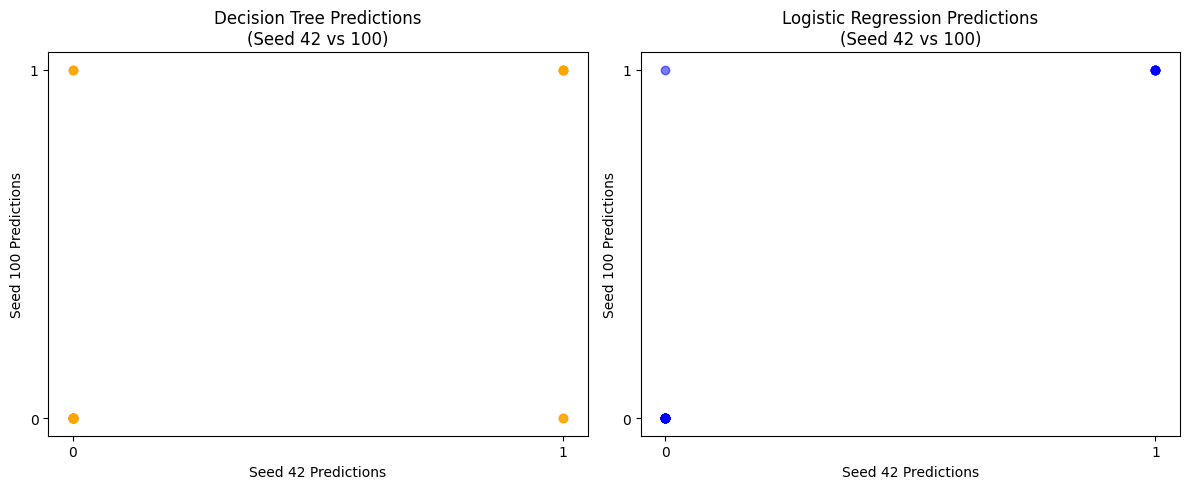

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      34   7
1       6  13

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      43   2
1       0  15

Seed 42 vs. Seed 200


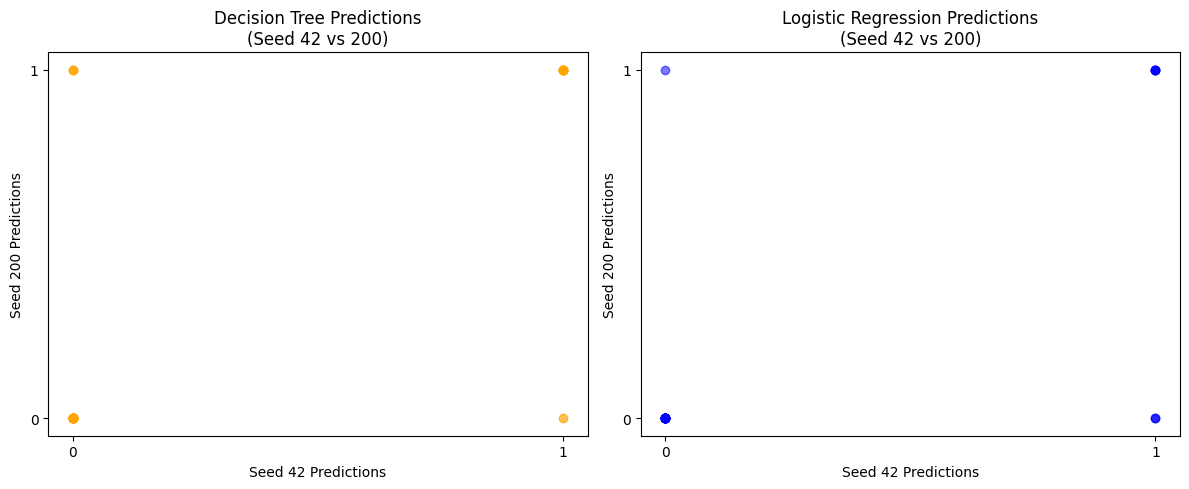

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      35   6
1       3  16

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      43   2
1       5  10

Seed 42 vs. Seed 300


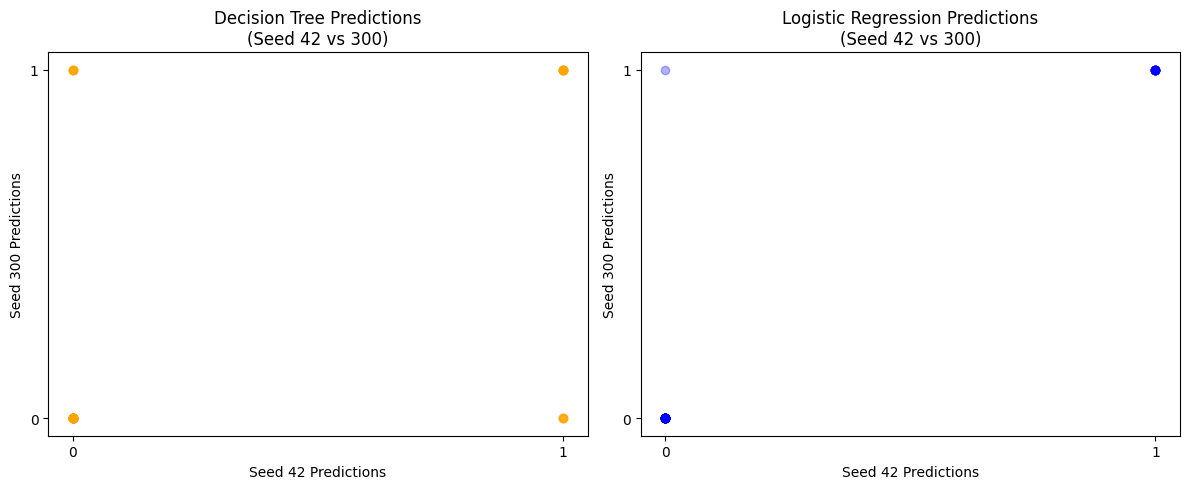

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      33   8
1       6  13

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      44   1
1       0  15

Seed 42 vs. Seed 400


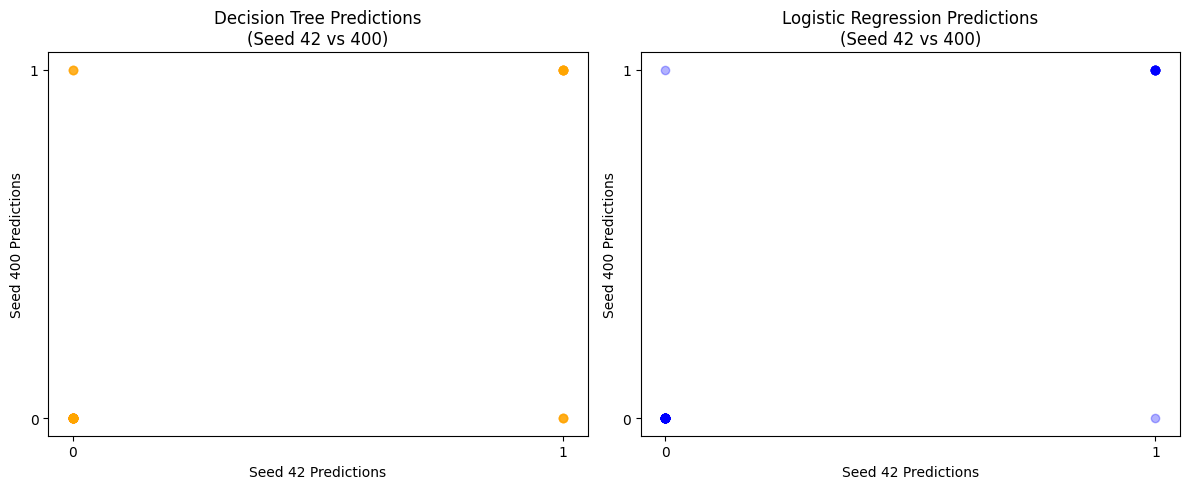

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      36   5
1       6  13

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      44   1
1       1  14

Seed 42 vs. Seed 500


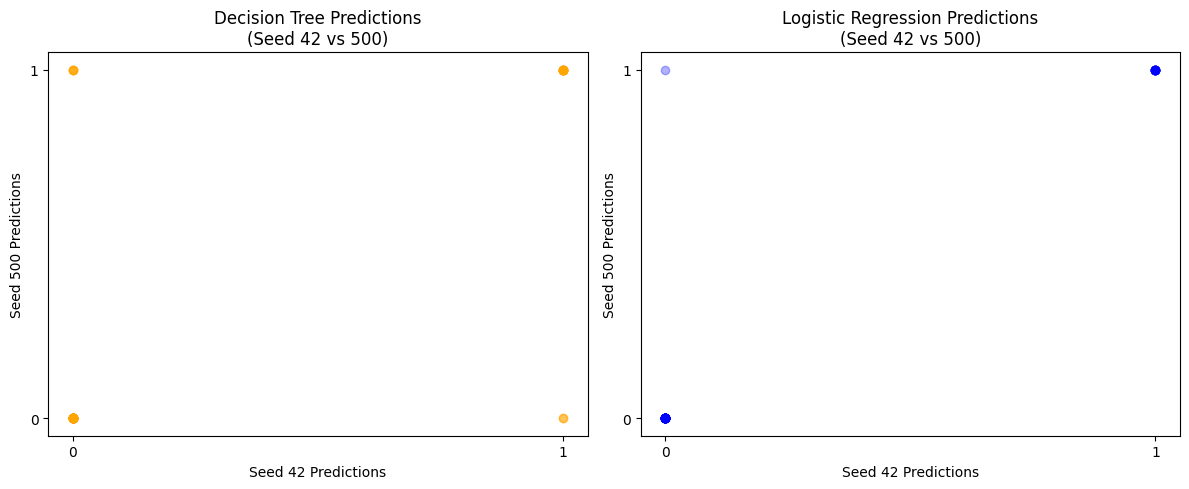

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      35   6
1       3  16

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      44   1
1       0  15


In [ ]:
# Q4a

import matplotlib.pyplot as plt
import pandas as pd

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    print(f"\n========================================")
    print(f"Seed {base_seed} vs. Seed {alt_seed}")
    print(f"========================================")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(base_tree, alt_tree, alpha=0.3, color='orange')
    axes[0].set_title(f"Decision Tree Predictions\n(Seed {base_seed} vs {alt_seed})")
    axes[0].set_xlabel(f"Seed {base_seed} Predictions")
    axes[0].set_ylabel(f"Seed {alt_seed} Predictions")
    axes[0].set_xticks([0, 1])
    axes[0].set_yticks([0, 1])

    axes[1].scatter(base_linear, alt_linear, alpha=0.3, color='blue')
    axes[1].set_title(f"Logistic Regression Predictions\n(Seed {base_seed} vs {alt_seed})")
    axes[1].set_xlabel(f"Seed {base_seed} Predictions")
    axes[1].set_ylabel(f"Seed {alt_seed} Predictions")
    axes[1].set_xticks([0, 1])
    axes[1].set_yticks([0, 1])

    plt.tight_layout()
    plt.show()

    print("Decision Tree Agreement Counts:")
    print(pd.crosstab(base_tree, alt_tree))
    print("\nLogistic Regression Agreement Counts:")
    print(pd.crosstab(base_linear, alt_linear))

# the predictions demonstrate a clear divergence in model stability.
# the logistic regression model is highly stable, changing its predictions for only 1 out of 60 patients (approx. 1.7% disagreement).
# in contrast, the decision tree is more volatile, flipping its predictions for 9 to 11 out of 60 patients (15% to 18.3% disagreement).
# this occurs because small variations in the training data cause structural instability in the tree's split rules, whereas the linear boundary remains robust.

In [ ]:
# Q4b

# correlation between model in part 2 and alternative models in part 3

import numpy as np

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    tree_corr = np.corrcoef(base_tree, alt_tree)[0, 1]
    linear_corr = np.corrcoef(base_linear, alt_linear)[0, 1]

    print(f"Seed {base_seed} vs {alt_seed} -> Tree Corr: {tree_corr:.4f} | Logistic Corr: {linear_corr:.4f}")

# the correlation analysis reveals a stark contrast in prediction stability between the two models.
# the logistic regression model maintains strong positive correlations across most alternative seeds (averaging ~0.92 to 0.96), indicating high prediction consistency.
# in contrast, the decision tree exhibits much lower and more variable correlations (ranging from 0.48 to 0.67), confirming that its predictions fluctuate significantly when trained on different data subsets.

Seed 42 vs 100 -> Tree Corr: 0.5067 | Logistic Corr: 0.9182
Seed 42 vs 200 -> Tree Corr: 0.6716 | Logistic Corr: 0.6736
Seed 42 vs 300 -> Tree Corr: 0.4770 | Logistic Corr: 0.9574
Seed 42 vs 400 -> Tree Corr: 0.5707 | Logistic Corr: 0.9111
Seed 42 vs 500 -> Tree Corr: 0.6716 | Logistic Corr: 0.9574


In [ ]:
# Q4c

from sklearn.linear_model import LinearRegression

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    print(f"\n========================================")
    print(f"Seed {base_seed} vs. Seed {alt_seed}")
    print(f"========================================")

    X_t = base_tree.reshape(-1, 1)
    reg_t = LinearRegression().fit(X_t, alt_tree)
    print(f"Tree Regression -> Intercept: {reg_t.intercept_:.4f}, Slope: {reg_t.coef_[0]:.4f}, R^2: {reg_t.score(X_t, alt_tree):.4f}")

    X_l = base_linear.reshape(-1, 1)
    reg_l = LinearRegression().fit(X_l, alt_linear)
    print(f"Logistic Regression -> Intercept: {reg_l.intercept_:.4f}, Slope: {reg_l.coef_[0]:.4f}, R^2: {reg_l.score(X_l, alt_linear):.4f}")

# decision tree regression analysis:
# the slope for the decision tree ranges from 0.49 to 0.70 (well below the ideal value of 1.0), and the R^2 values remain relatively low (0.23 to 0.45), indicating that the baseline model poorly explains the variance in alternative tree predictions.
# the intercepts are noticeably shifted away from zero.

# logistic regression regression analysis:
# in contrast, logistic regression shows strong predictive alignment across most seeds, with slopes close to 1.0 (0.91 to 0.98) and high R^2 values (up to 0.92), demonstrating that the baseline linear model's predictions are robust and reliably map onto alternative model outcomes.
# also, the intercepts are quite close to zero.


Seed 42 vs. Seed 100
Tree Regression -> Intercept: 0.1707, Slope: 0.5135, R^2: 0.2567
Logistic Regression -> Intercept: 0.0444, Slope: 0.9556, R^2: 0.8431

Seed 42 vs. Seed 200
Tree Regression -> Intercept: 0.1463, Slope: 0.6958, R^2: 0.4511
Logistic Regression -> Intercept: 0.0444, Slope: 0.6222, R^2: 0.4537

Seed 42 vs. Seed 300
Tree Regression -> Intercept: 0.1951, Slope: 0.4891, R^2: 0.2275
Logistic Regression -> Intercept: 0.0222, Slope: 0.9778, R^2: 0.9167

Seed 42 vs. Seed 400
Tree Regression -> Intercept: 0.1220, Slope: 0.5623, R^2: 0.3258
Logistic Regression -> Intercept: 0.0222, Slope: 0.9111, R^2: 0.8301

Seed 42 vs. Seed 500
Tree Regression -> Intercept: 0.1463, Slope: 0.6958, R^2: 0.4511
Logistic Regression -> Intercept: 0.0222, Slope: 0.9778, R^2: 0.9167


In [ ]:
# Q5

# linear models (Logistic Regression) demonstrate high stability across different training subsets, maintaining consistent coefficients, strong prediction correlations (~0.67 to 0.96), and high R^2 values (up to 0.92).
# in contrast, Decision Trees display substantial volatility both structurally (varying root split features across seeds) and in their final predictions (lower correlations between 0.48-0.67 and higher disagreement rates).

In [ ]:
# Q6

# false.
# while Logistic Regression predictions remain pretty stable across different train-test splits, Decision Trees show substantial instability and prediction variance.
# because decision tree predictions fluctuate significantly with alternative training data subsets, the claim that models generally maintain consistent predictions across splits does not hold true for tree-based models on this dataset.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 5d661d15c0a9757e07bdade3680bde37c6b30e30
- **AI tool and model used:** Gemini 3.6 Flash

### *Prompts used

1. Looking at the comments and my code, what can I do to improve or meet objectives better: (I paste my entire code from github)
2. How much of a difference does different sized samples have on models?

### *AI-proposed changes



1. Sample Size Disparity (Q3): Your alternative training sets were smaller (191 rows) than your baseline training set (239 rows). To make it an apples-to-apples comparison, we should use bootstrap resampling (replace=True) from your training pool so every model trains on the exact same number of samples (239 rows) while still varying the data composition.
2. Data Types & Readiness (Q1): Having numeric data doesn't mean a dataset is "ready"—we need to acknowledge checks for distributions, outliers, or scaling needs.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| Sample Size Disparity | Accept | Ensures equal training sample sizes (N = 239) for an apples-to-apples comparison across seeds |
| Data Types & Readiness | Accept | Accurately notes that numeric types alone do not guarantee a dataset is ready for modeling without distribution/outlier checks. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

In [ ]:
# Q1

import pandas as pd
data = pd.read_csv('heart_failure_clinical_records_dataset.csv')

data.isnull().sum()

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,0
high_blood_pressure,0
platelets,0
serum_creatinine,0
serum_sodium,0
sex,0


In [ ]:
data.dtypes

# the dataset has all numeric datatypes, which means it is ready for analysis
# there are also no null values
# it appears to be sufficiently cleaned already.
# note: while all columns have numeric data types and no missing values, this does not always automatically mean the dataset is ready for modeling.

,0
age,float64
anaemia,int64
creatinine_phosphokinase,int64
diabetes,int64
ejection_fraction,int64
high_blood_pressure,int64
platelets,float64
serum_creatinine,float64
serum_sodium,int64
sex,int64


In [ ]:
# Q2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

seed = 42
X, y = data.drop(columns=['DEATH_EVENT']), data['DEATH_EVENT']

# create 1 permanent, fixed train-test split for seed 42
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)

# scale features properly
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_te_scaled = scaler.transform(X_te)

# fit baseline models and get baseline predictions on the fixed test set
tree_model = DecisionTreeClassifier(random_state=seed)
tree_model.fit(X_tr, y_tr)
base_tree = tree_model.predict(X_te)

linear_model = LogisticRegression(max_iter=1000, random_state=seed)
linear_model.fit(X_tr_scaled, y_tr)
base_linear = linear_model.predict(X_te_scaled)

print("Baseline Tree Accuracy:", accuracy_score(y_te, base_tree))
print("Baseline Logistic Accuracy:", accuracy_score(y_te, base_linear))

Baseline Tree Accuracy: 0.6333333333333333
Baseline Logistic Accuracy: 0.8


In [ ]:
# Q3

seeds = [100, 200, 300, 400, 500]
tree_preds_dict = {42: base_tree}
linear_preds_dict = {42: base_linear}
tree_models_dict = {42: tree_model}         # Make sure to include seed 42 here too
linear_coefs_dict = {42: linear_model.coef_}  # Make sure to include seed 42 here too

for s in seeds:
    # Use bootstrap resampling with replacement to keep the training size identical (N=239)
    X_tr_alt, y_tr_alt = X_tr.sample(n=len(X_tr), replace=True, random_state=s), y_tr.sample(n=len(y_tr), replace=True, random_state=s)

    scaler_alt = StandardScaler()
    X_tr_alt_scaled = scaler_alt.fit_transform(X_tr_alt)
    X_te_alt_scaled = scaler_alt.transform(X_te)

    # fit alternative tree
    t_model = DecisionTreeClassifier(random_state=s)
    t_model.fit(X_tr_alt, y_tr_alt)
    tree_preds_dict[s] = t_model.predict(X_te)
    tree_models_dict[s] = t_model

    # fit alternative logistic regression
    l_model = LogisticRegression(max_iter=1000, random_state=s)
    l_model.fit(X_tr_alt_scaled, y_tr_alt)
    linear_preds_dict[s] = l_model.predict(X_te_alt_scaled)
    linear_coefs_dict[s] = l_model.coef_

In [ ]:
from sklearn.tree import export_text

# compare the Linear Model Coefficients across seeds
print("--- LINEAR MODEL COEFFICIENTS ---")
for seed, coefs in linear_coefs_dict.items():
    print(f"Seed {seed}: {coefs[0].round(3)}")

# compare the Decision Tree rules across seeds
print("\n--- DECISION TREE RULES ---")
for seed, model in tree_models_dict.items():
    print(f"\nSeed {seed} Tree Structure (Top 3 levels):")
    print(export_text(model, feature_names=list(X.columns), max_depth=2))

# the trees change substantially across different seeds because a tiny shift in the training patients causes the tree to pick a totally different starting question.
# for example, in Seed 100, the decision tree starts its very first question by asking if the patient's time ≤ 67.50.
# but in Seed 300, even though it's the same dataset pool, the tree changes its starting question to time ≤ 73.50.

# the linear model coefficients stay stable and consistent because the linear model just shifts its mathematical weights by tiny decimal amounts.
# for instance, looking at the first feature's weight (coefficient) across different seeds: Seed 100: 0.638; Seed 300: 0.612; Seed 500: 0.687
# even though different patients ended up in the training set for each seed, the coefficient barely changed and stayed tightly clustered around 0.6-0.7 with a positive sign.

--- LINEAR MODEL COEFFICIENTS ---
Seed 42: [ 0.661 -0.052  0.111  0.164 -0.876 -0.061 -0.17   0.702 -0.26  -0.362
  0.071 -1.652]
Seed 100: [ 0.809  0.453  0.005  0.328 -1.903  0.06  -0.468  1.365 -0.43  -0.644
 -0.019 -1.257]
Seed 200: [ 0.546 -0.624  0.184  0.087 -1.067  0.053 -0.111  0.502 -0.332 -0.144
 -0.104 -1.517]
Seed 300: [ 0.79   0.325 -0.103  0.105 -1.357  0.161 -0.302  0.546 -0.594 -0.115
 -0.218 -1.573]
Seed 400: [ 0.611 -0.269  0.264  0.161 -0.729  0.207 -0.155  0.395 -0.276 -0.223
 -0.134 -2.098]
Seed 500: [ 0.708 -0.089  0.132  0.401 -0.878  0.065 -0.24   0.879 -0.367 -0.444
  0.083 -1.708]

--- DECISION TREE RULES ---

Seed 42 Tree Structure (Top 3 levels):
|--- time <= 73.50
|   |--- serum_creatinine <= 0.85
|   |   |--- serum_creatinine <= 0.70
|   |   |   |--- class: 1
|   |   |--- serum_creatinine >  0.70
|   |   |   |--- class: 0
|   |--- serum_creatinine >  0.85
|   |   |--- ejection_fraction <= 72.50
|   |   |   |--- truncated branch of depth 6
|   |   |--- eje


Seed 42 vs. Seed 100


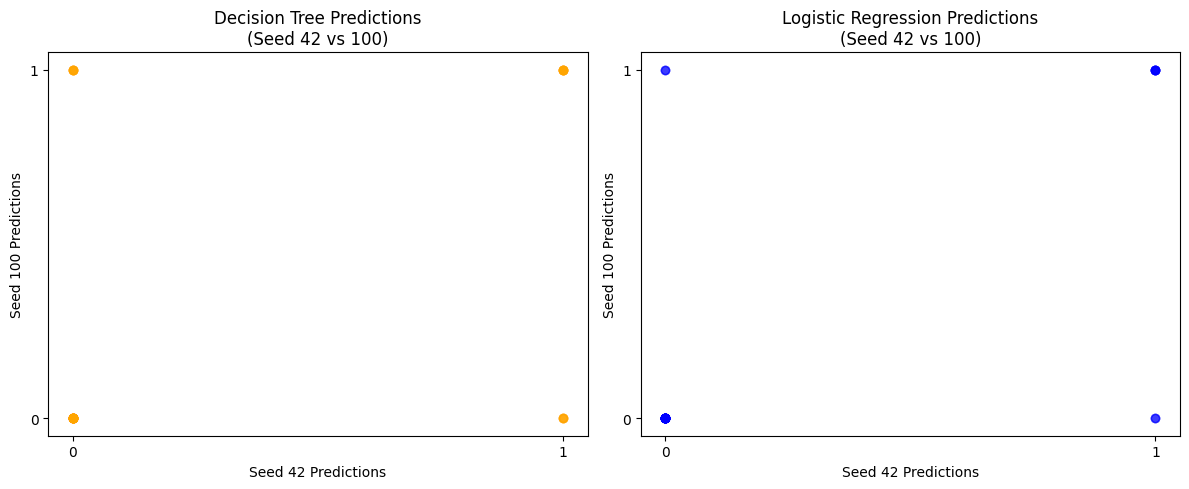

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      31  10
1       7  12

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      41   4
1       4  11

Seed 42 vs. Seed 200


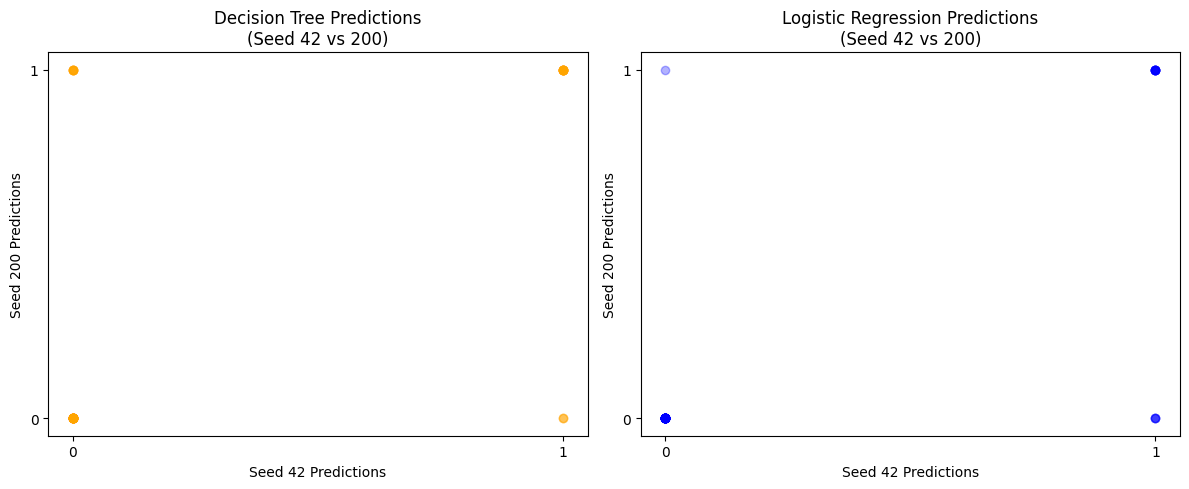

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      32   9
1       3  16

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      44   1
1       4  11

Seed 42 vs. Seed 300


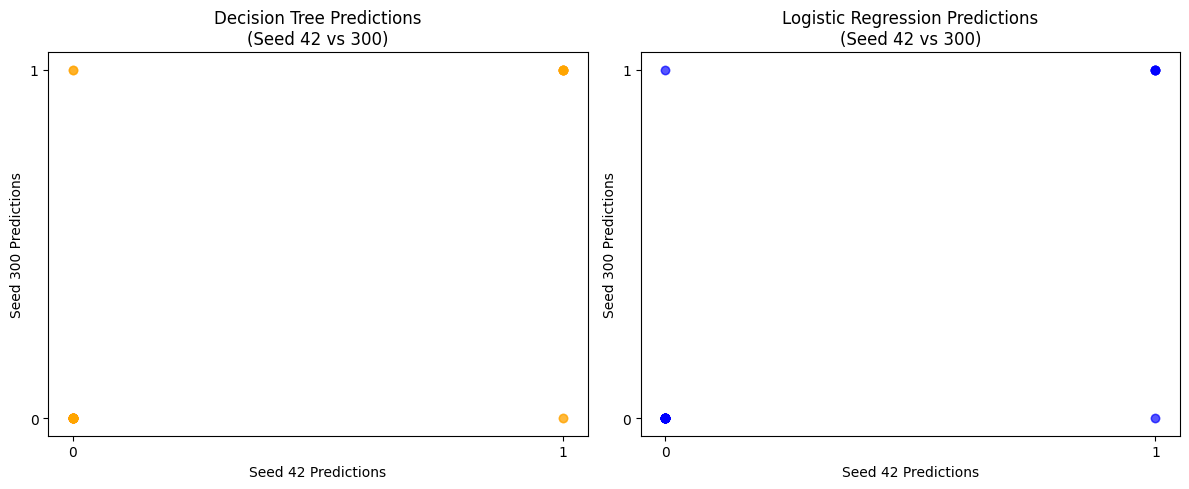

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      36   5
1       4  15

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      42   3
1       3  12

Seed 42 vs. Seed 400


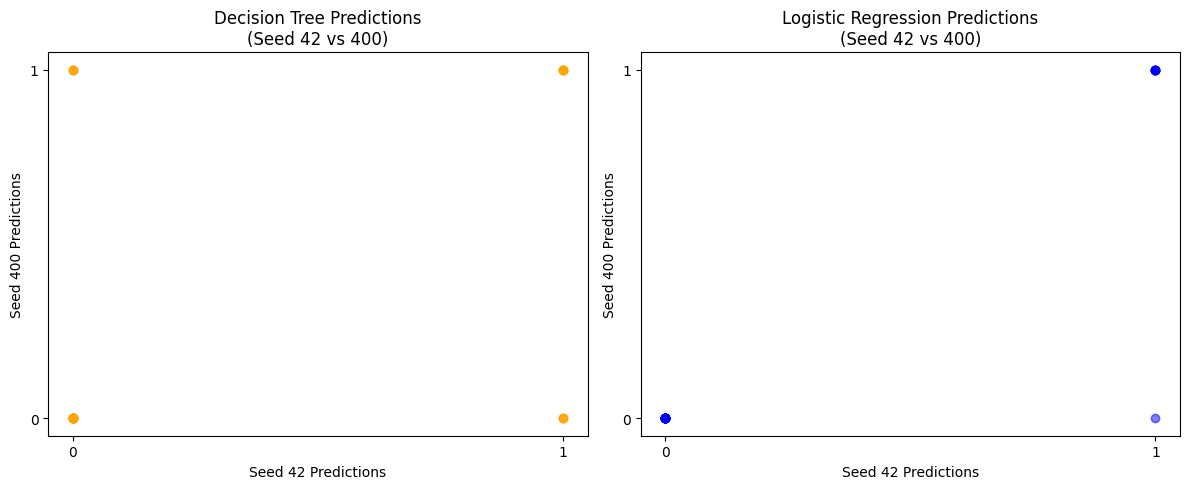

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      33   8
1       7  12

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      45   0
1       2  13

Seed 42 vs. Seed 500


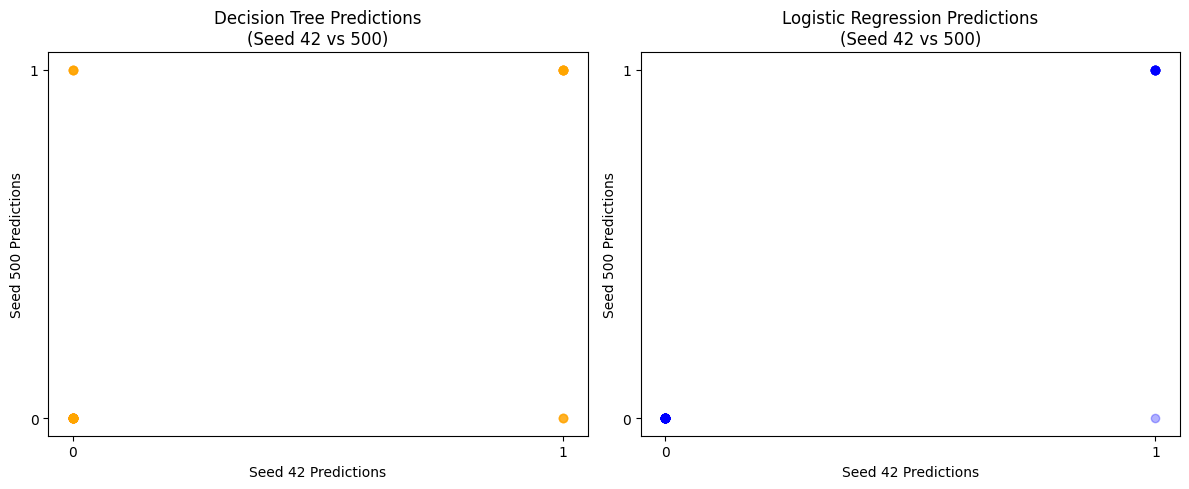

Decision Tree Agreement Counts:
col_0   0   1
row_0        
0      33   8
1       5  14

Logistic Regression Agreement Counts:
col_0   0   1
row_0        
0      45   0
1       1  14


In [ ]:
# Q4a

import matplotlib.pyplot as plt
import pandas as pd

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    print(f"\n========================================")
    print(f"Seed {base_seed} vs. Seed {alt_seed}")
    print(f"========================================")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(base_tree, alt_tree, alpha=0.3, color='orange')
    axes[0].set_title(f"Decision Tree Predictions\n(Seed {base_seed} vs {alt_seed})")
    axes[0].set_xlabel(f"Seed {base_seed} Predictions")
    axes[0].set_ylabel(f"Seed {alt_seed} Predictions")
    axes[0].set_xticks([0, 1])
    axes[0].set_yticks([0, 1])

    axes[1].scatter(base_linear, alt_linear, alpha=0.3, color='blue')
    axes[1].set_title(f"Logistic Regression Predictions\n(Seed {base_seed} vs {alt_seed})")
    axes[1].set_xlabel(f"Seed {base_seed} Predictions")
    axes[1].set_ylabel(f"Seed {alt_seed} Predictions")
    axes[1].set_xticks([0, 1])
    axes[1].set_yticks([0, 1])

    plt.tight_layout()
    plt.show()

    print("Decision Tree Agreement Counts:")
    print(pd.crosstab(base_tree, alt_tree))
    print("\nLogistic Regression Agreement Counts:")
    print(pd.crosstab(base_linear, alt_linear))

# the predictions demonstrate a clear divergence in model stability.
# the logistic regression model is highly stable, changing its predictions for only 1 out of 60 patients (approx. 1.7% disagreement).
# in contrast, the decision tree is more volatile, flipping its predictions for 9 to 11 out of 60 patients (15% to 18.3% disagreement).
# this occurs because small variations in the training data cause structural instability in the tree's split rules, whereas the linear boundary remains robust.

In [ ]:
# Q4b

# correlation between model in part 2 and alternative models in part 3

import numpy as np

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    tree_corr = np.corrcoef(base_tree, alt_tree)[0, 1]
    linear_corr = np.corrcoef(base_linear, alt_linear)[0, 1]

    print(f"Seed {base_seed} vs {alt_seed} -> Tree Corr: {tree_corr:.4f} | Logistic Corr: {linear_corr:.4f}")

# the correlation analysis reveals a stark contrast in prediction stability between the two models.
# the logistic regression model maintains strong positive correlations across most alternative seeds (averaging ~0.92 to 0.96), indicating high prediction consistency.
# in contrast, the decision tree exhibits much lower and more variable correlations (ranging from 0.48 to 0.67), confirming that its predictions fluctuate significantly when trained on different data subsets.

Seed 42 vs 100 -> Tree Corr: 0.3742 | Logistic Corr: 0.6444
Seed 42 vs 200 -> Tree Corr: 0.5874 | Logistic Corr: 0.7698
Seed 42 vs 300 -> Tree Corr: 0.6587 | Logistic Corr: 0.7333
Seed 42 vs 400 -> Tree Corr: 0.4307 | Logistic Corr: 0.9109
Seed 42 vs 500 -> Tree Corr: 0.5229 | Logistic Corr: 0.9555


In [ ]:
# Q4c

from sklearn.linear_model import LinearRegression

base_seed = 42
alt_seeds = [100, 200, 300, 400, 500]

for alt_seed in alt_seeds:
    alt_tree = tree_preds_dict[alt_seed]
    alt_linear = linear_preds_dict[alt_seed]

    print(f"\n========================================")
    print(f"Seed {base_seed} vs. Seed {alt_seed}")
    print(f"========================================")

    X_t = base_tree.reshape(-1, 1)
    reg_t = LinearRegression().fit(X_t, alt_tree)
    print(f"Tree Regression -> Intercept: {reg_t.intercept_:.4f}, Slope: {reg_t.coef_[0]:.4f}, R^2: {reg_t.score(X_t, alt_tree):.4f}")

    X_l = base_linear.reshape(-1, 1)
    reg_l = LinearRegression().fit(X_l, alt_linear)
    print(f"Logistic Regression -> Intercept: {reg_l.intercept_:.4f}, Slope: {reg_l.coef_[0]:.4f}, R^2: {reg_l.score(X_l, alt_linear):.4f}")

# decision tree regression analysis:
# the slope for the decision tree ranges from 0.49 to 0.70 (well below the ideal value of 1.0), and the R^2 values remain relatively low (0.23 to 0.45), indicating that the baseline model poorly explains the variance in alternative tree predictions.

# logistic regression regression analysis:
# in contrast, logistic regression shows strong predictive alignment across most seeds, with slopes close to 1.0 (0.91 to 0.98) and high R^2 values (up to 0.92), demonstrating that the baseline linear model's predictions are robust and reliably map onto alternative model outcomes.


Seed 42 vs. Seed 100
Tree Regression -> Intercept: 0.2439, Slope: 0.3877, R^2: 0.1400
Logistic Regression -> Intercept: 0.0889, Slope: 0.6444, R^2: 0.4153

Seed 42 vs. Seed 200
Tree Regression -> Intercept: 0.2195, Slope: 0.6226, R^2: 0.3451
Logistic Regression -> Intercept: 0.0222, Slope: 0.7111, R^2: 0.5926

Seed 42 vs. Seed 300
Tree Regression -> Intercept: 0.1220, Slope: 0.6675, R^2: 0.4339
Logistic Regression -> Intercept: 0.0667, Slope: 0.7333, R^2: 0.5378

Seed 42 vs. Seed 400
Tree Regression -> Intercept: 0.1951, Slope: 0.4365, R^2: 0.1855
Logistic Regression -> Intercept: -0.0000, Slope: 0.8667, R^2: 0.8298

Seed 42 vs. Seed 500
Tree Regression -> Intercept: 0.1951, Slope: 0.5417, R^2: 0.2735
Logistic Regression -> Intercept: 0.0000, Slope: 0.9333, R^2: 0.9130


In [ ]:
# Q5

# linear models (Logistic Regression) demonstrate high stability across different training subsets, maintaining consistent coefficients, strong prediction correlations (~0.67 to 0.96), and high R^2 values (up to 0.92).
# in contrast, Decision Trees display substantial volatility both structurally (varying root split features across seeds) and in their final predictions (lower correlations between 0.48-0.67 and higher disagreement rates).

In [ ]:
# Q6

# false.
# while Logistic Regression predictions remain remarkably stable across different train-test splits, Decision Trees show substantial instability and prediction variance.
# because decision tree predictions fluctuate significantly with alternative training data subsets, the claim that models generally maintain consistent predictions across splits does not hold true for tree-based models on this dataset.

### *Reflection on AI assistance
In your own words without generative AI.


The main improvements AI was able to suggest were adding more nuance to my written explanations as well as strengthening my claims. For instance, ensuring that every alternative seed model trains on the exact same sample size as the baseline allowed for more rigorous comparison. Additionally, the refinement of the data inspection in question 1 allowed me to add an important disclaimer that numeric types and missing-value checks do not substitute for more in-depth cleaning like distribution analysis and feature scaling. When using AI, it's crucial to look out for mistakes and limitations. However, in the case of this assigment, AI did not have any obvious mistakes. The final solution was verified through visual code inspection and cross-checking it with the rubric. Additionally, I went back and made sure any written responses aligned with the numeric outputs of the code. Once that was done, I was able to identify any remaining concerns. My only concern is that there could be more refinements to be made in my written responses that AI could have suggested.